Import the necessary packages

In [ ]:
import numpy as np
import polars as pl
import networkx as nx
import matplotlib.pyplot as plt         

Load the Networks that are Constructed Using Only the 69 Students in All Three Data Sets

In [ ]:
import pickle
from pathlib import Path

def load(path):
    with Path(path).open("rb") as f:                    # open the pickle file
        return pickle.load(f)                           # return whatever object is stored

shared_temporal        = load("../Data/Cleaned/shared_temporal_networks.pkl")
G_friendship_shared    = load("../Data/Cleaned/shared_students_friendship_network.pkl")
G_contact_diary_shared = load("../Data/Cleaned/shared_students_contact_diary_network.pkl")

Verify that the network cleaning was done correctly, to only include students that are in all three networks

In [ ]:
# give these networks a shorter name
G_friend = G_friendship_shared
G_diary  = G_contact_diary_shared
networks_by_time = shared_temporal

# finds the all of the students that appear in the temporal networks sensor data
temporal_nodes = set().union(*[set(G.nodes) for G in networks_by_time.values()])   
# prints the number of nodes in each network; we expect each to be the same as the total number of students
print(len(temporal_nodes), G_friend.number_of_nodes(), G_diary.number_of_nodes())  
# now, also want to ensure the student identities are the same, not just the same number of students 
print("same students in all three:", temporal_nodes == set(G_friend.nodes) == set(G_diary.nodes)) # if it prints True, then the networks contain all the same student IDs
# verifying that both the friendship and contact diary networks are directed
print(type(G_friend), type(G_diary))                    

69 69 69
same students in all three: True
<class 'networkx.classes.digraph.DiGraph'> <class 'networkx.classes.digraph.DiGraph'>


Set the parameters to be used in the SIR simulations

In [4]:
DT = 24 * 3600                            # this sets the period of time that an infected individual can infect others
                                                # infectious period = 24 h (in seconds, because this is the time-stamp data units of time)
BETA = 0.1                                # the transmission rate of the disease
N_REPS = 100                              # how many iterations of the simulation to be completed at for each strategy and immunization coverage level
COVERAGES = [0.1, 0.2, 0.3, 0.4, 0.5]     # the coverage level, which is the fraction of students that are immunized
rng = np.random.default_rng(42)           # fixed seed allows for repeatable results even with a stochastic model

Save all the contacts in the temporal network into arrays that can be used in the SIR model

In [5]:
# creates an array of the students across all networks 
ids = np.array(sorted(set().union(*[set(G.nodes) for G in networks_by_time.values()], G_friend.nodes, G_diary.nodes))) 
N = len(ids)                                  # should be 69; we verified this earlier 

# creates an array of the time stamps with a network that contain at least one edge (meaning at least one contact)
ts = np.array(sorted(t for t, G in networks_by_time.items() if G.number_of_edges() > 0))
# empty lists that will be filled with the time stamps, student 1, and student 2 for each contact
t_list, i_list, j_list = [], [], [] 

# iterate over every timestamp in the array of time stamps with at least one contact
for t in ts:                                  
    # for each edge in the network at the timestamp the loop is iterating over, add the time stamp and the corresponding IDs of the two interacting students 
    for u, v in networks_by_time[t].edges():  
        t_list.append(t); i_list.append(u); j_list.append(v)

# convert each list to a numpy array that will be used in the SIR simulations
t_arr = np.array(t_list)                      # time of each contact
i_arr = np.searchsorted(ids, i_list)          # student 1 in the contact
j_arr = np.searchsorted(ids, j_list)          # student 2 in the contact
bounds = np.append(np.searchsorted(t_arr, ts), len(t_arr))   # stores the start and end indices of all the contacts at a given timestamp; 
                                                        # contacts at ts[k] = rows bounds[k]:bounds[k+1] in the t_arr, i_arr, and j_arr arrays  

# print summary statistics of the dataset
print("students:", N)
print("time stamps:", len(ts))
print("contacts:", len(t_arr))

students: 69
time stamps: 6814
contacts: 26060


Compute the temporal degree for each student

In [6]:
deg = np.bincount(i_arr, minlength=N) + np.bincount(j_arr, minlength=N)   # find the total contacts per student, since each student can appear in either array
temporal_degree = deg / len(ts)               # divide the total contacts by the number of time stamps to get the average contacts per time stamp

# print("students with no contacts:", int((deg == 0).sum()))   # should be 0 or very few

Define the SIR model as a function.

In [7]:
# define a function that uses the contact data to simulate the spread of an infection (SIR model) - Same as found in 11-09-2026_code004.ipynb
def sir(immune, seed, k0, beta, dt, rng, horizon=np.inf):
    """One outbreak. immune = student indices; seed = student index; k0 = start time-stamp index;
    horizon = max seconds the outbreak may run (inf = no limit). Returns # students infected (seed included)."""
    inf = np.full(N, np.inf)          # infection time per student (inf = never infected)
    blocked = np.zeros(N, bool)         # True = immunized
    blocked[np.asarray(immune, dtype=int)] = True   # mark immunized students
    inf[seed] = ts[k0] - 20           # seed infected one step before start (can spread immediately)
    last = ts[k0]               # time of most recent infection
    for k in range(k0, len(ts)):         # replay time stamps in order
        t = ts[k]                  # current time
        if t - last > dt or t - ts[k0] > horizon:   # nobody infectious (>24 h) OR time limit reached
            break                    # outbreak over
        a = i_arr[bounds[k]:bounds[k+1]]      # student 1 of each contact now
        b = j_arr[bounds[k]:bounds[k+1]]      # student 2 of each contact now
        new = []                  # newly infected this step
        for u, v in ((a, b), (b, a)):         # check both directions
            can_pass = (inf[u] < t) & (t - inf[u] <= dt)       # u infectious (infected, <24 h ago)
            can_catch = np.isinf(inf[v]) & ~blocked[v]         # v susceptible (never infected, not immune)
            hit = can_pass & can_catch & (rng.random(len(u)) < beta)   # roll the transmission chance
            new.append(v[hit])                # save who got infected
        new = np.unique(np.concatenate(new))  # combine, remove repeats
        if len(new):           # anyone newly infected?
            inf[new] = t              # record infection time (after loop: no chaining in one step)
            last = t           # update last infection time
    return int(np.isfinite(inf).sum())     # count of infected students

Define a function that randomly selects when the infection starts and what student it begins with.

In [8]:
# find the end of the first day in the timestamp array 
DAY1_END = np.searchsorted(ts, ts[0] + 24*3600)  

# this function will use the indices of immunized individuals and the random number generator that is seeded for reproducibility
def draw_start_and_seed(immune, rng):
    while True:                              
        # select a random timestamp that occurs on day 1 for the start of the outbreak
        k0 = rng.integers(0, DAY1_END)        
        # identify all the students that are present in the contacts at this timestamp - only keeping thier indices a single time, even if they are in multiple contacts at the timestamp
        present = np.unique(np.r_[i_arr[bounds[k0]:bounds[k0+1]], j_arr[bounds[k0]:bounds[k0+1]]])   
        # of the present students, remove any that are immunized
        candidates = np.setdiff1d(present, immune)   
        # if there are any non-immunized students present, we can select one as the seed for the outbreak
        # if no non-immunized students are present, we will retry selecting a different timestamp
        if len(candidates):  # if the length of the candidates array is greater than zero, there are non-immunized students present, so we can select a seed from them
            return k0, rng.choice(candidates) # random seed from them


Select a new value of BETA. This is because the contact sensor network has been reduced from 327 students to 69 students, so there are less interactions recorded in this data, so may need a larger beta for the simulations.

In [9]:
# this loop will iterate over candidate values of infection transmission rate (beta)
for b in [0.02, 0.05, 0.1, 0.2, 0.4]:         
    # create a list to store the sizes of outbreaks for each candidate beta value
    sizes = []
    # this loop will iterate 50 times
    for _ in range(50):                     
        # draw a random start time and seed for the outbreak, using the function created in the previous cell
        k0, s = draw_start_and_seed([], rng)
        # run the SIR model starting from the selected seed and start time, and append the outbreak size to the sizes list
        sizes.append(sir([], s, k0, b, DT, rng))
    # print the mean share of infected individuals for the current beta value, and then repeat these steps for each candidate beta value
    print(b, "mean share infected:", round(np.mean(sizes) / N, 2))  

# We will use the beta value that results in a mean share of infected individuals between 0.3 and 0.5 for further analysis, so BETA = 0.1 has been modified in the parameters cell above

0.02 mean share infected: 0.09
0.05 mean share infected: 0.21
0.1 mean share infected: 0.31
0.2 mean share infected: 0.63
0.4 mean share infected: 0.81


Define a function for computing reachability - same as found in ```11-09-2026_code004.ipynb```

In [10]:
ev_k = np.repeat(np.arange(len(ts)), np.diff(bounds))   # this gives the time-stamp index of each contact row

def compute_reachability(horizon, n_starts, rng):
    # create an array of zeros for each student
    score = np.zeros(N)                                 
    # this will iterate over each student
    for n in range(N): 
        # get the contact rows for the current student of the loop iteration
        rows_n = np.where((i_arr == n) | (j_arr == n))[0]   
        # finds the unique time stamps where the student has a contact, using the list of contacts from the row above
        starts = np.unique(ev_k[rows_n])   
        # we want the start times that occur on day 1 only, because this is when we are modeling the initial spread of the disease
        starts = starts[starts < DAY1_END]
        # if the student has no contacts on day 1, then thier score stays 0, and continue without them          
        if len(starts) == 0:                            
            continue
        # choose a subset of the start times to test
        chosen = rng.choice(starts, min(n_starts, len(starts)), replace=False)  
        # run a SIR simulation of an outbreak, but beginning with no immunized students, and beginning with the student n (of the loops iteration)
        # as the starting infected invidual
        score[n] = np.mean([sir([], n, k, 1.0, DT, rng, horizon=horizon) - 1 for k in chosen]) # horizon is the length of the simulation
    return score

In [11]:
scan = {}                                               # horizon (hours) -> scores
# iterate the loop over the possible horizon lengths to test 
for hours in [0.5, 1, 2, 4, 8]:                         
    # compute the reachability for the current horizon length (in seconds), beginning with n = 2 (trials per student)
    r = compute_reachability(hours * 3600, 2, rng)
    # add a new entry to the scan dictionary, where the reachability scores for the current horizon are stored
    scan[hours] = r                                     
    # compute statistics for the current horizon's reachability scores and print these
    print(f"{hours} h: min/median/max = {r.min():.0f} / {np.median(r):.0f} / {r.max():.0f}, "
          f"distinct = {len(np.unique(r.round(1)))}")   # spread of scores (want wide spread, many distinct)

0.5 h: min/median/max = 0 / 3 / 14, distinct = 21
1 h: min/median/max = 0 / 6 / 17, distinct = 28
2 h: min/median/max = 0 / 10 / 21, distinct = 33
4 h: min/median/max = 0 / 21 / 48, distinct = 43
8 h: min/median/max = 0 / 29 / 60, distinct = 49


Reachability continued: we selected the horizon length to be 4 hours. This means that the max time length for a simulation to run to determine reachibility will be 4 hours. We selected this because it has a wide variety of scores of reachability; however, we likely could have also selected 8 hours. The important distinction is avoiding a horizon length that is able to reach almost all students (too long) or has consistently low reachability (too short). 

In [12]:
# horizon length that was selected from the scan is 4 hours, so set this as a parameter
HORIZON_HOURS = 4                                      
# compute the reachability scores for the selected horizon length for each student, where each student has 5 randomly selected start times, and these are averaged to get the final score
reachability = compute_reachability(HORIZON_HOURS * 3600, 5, rng)   
# statistics about the reachability scores for the selected horizon length
print("min / median / max:", reachability.min(), np.median(reachability), reachability.max())

min / median / max: 0.0 18.6 35.666666666666664


Data Needed for the Final Figure Preparations: 

Simulating the Mean Baseline Spread without Immunization

In [13]:
# create an empty list to store the number of infected individuals from SIR simulations without any immunization
baseline = []                                
# iterate this loop over the number of times defined by N_REPS, which is defined as a parameter = 100 at the top
for _ in range(N_REPS): 
    # find a random start time and seed for the simulation, with nobody immune ([] means 0 students are immune)
    k0, s = draw_start_and_seed([], rng)      
    # complete an SIR trial, and save the number of infected students into the list called baseline
    baseline.append(sir([], s, k0, BETA, DT, rng))   
# compute the mean share of infected students in the baseline scenario, by averaging the number of infected students across all runs, then dividing 
# this by the total number of students (to get the fraction of infected students), and round this value to 2 decimal places 
print("baseline mean share infected:", round(np.mean(baseline) / N, 2))  

baseline mean share infected: 0.34


Student Selection for Each Targetting Measure

In [14]:
# create a mapping from student IDs (in the list called ids) to their index in the array called idx
idx = {s: k for k, s in enumerate(ids)}                 

# create a function that turns a dictionary of student scores into an array, such that it is in the same order of those in ids, so that the student's 
# score will have the same index that corresponds to their student ID
def to_array(d):                                        
    # begin with an array of zeros for each student - ensures that each student has an entry
    arr = np.zeros(N)
    # for each item in the dictionary of scores, place the value at the correct index in the array based on thier student id (using the idx mapping)
    for s, v in d.items():
        arr[idx[s]] = v
    return arr

    # store the measures of degree and reachability for the temporal sensor data, and calculate the degree and betweenness for the contact diary and friendship networks 
    # each key in the dictionary is one of the measures of centrality for one of the networks, and the values are the corresponding scores for each student, using the indexing
measures = {                                          
    "temporal_degree":    temporal_degree,
    "reachability":       reachability,
    "diary_degree":       to_array(dict(G_diary.degree())),              # includes both in + out because this is a directed graph
    "diary_betweenness":  to_array(nx.betweenness_centrality(G_diary)),
    "friend_degree":      to_array(dict(G_friend.degree())),
    "friend_betweenness": to_array(nx.betweenness_centrality(G_friend)), 
}

In [15]:
# a list of all the strategies to be used in the SIR model, just using their names
strategies = ["random"] + list(measures)               

Find the Top Ranked Students for Each Measure

In [16]:
# creating a data frame, with columns including the student ID, and then one column for each measure in the dictionary
rank_table = pl.DataFrame({"student": ids, **measures})   # this means there is one row per student
# for every measure in the dictionary, add a corresponding rank column to the rank table, where 1 is the highest
for m in measures:                                      
    rank_table = rank_table.with_columns(pl.col(m).rank("min", descending=True).alias(m + "_rank"))
rank_table.write_csv("student_rankings.csv")            # save as a csv 

# rank top 10 students (using their student ID) by each measure, side by side in a table
top10 = pl.DataFrame({m: ids[np.argsort(-v, kind="stable")][:10] for m, v in measures.items()})
top10 = top10.with_row_index("rank", offset=1) # this means that the top rank is 1
print(top10)

# how similar are the rankings across different measures, where a correlation of 1 means they have the same order
rank_cols = [m + "_rank" for m in measures] # creates a list of column names using the measure names from the dictionary of measures + "_rank"
# from the rank_table, but using only the columns in the list above, find the correlation between the rankings of different measures
corr = np.corrcoef(rank_table.select(rank_cols).to_numpy().T) 
# print the correlation matrix as a DataFrame with the measure names as both the rows and columns, rounding the correlation to 2 decimals
print(pl.DataFrame(corr.round(2), schema=list(measures)).with_columns(pl.Series("measure", list(measures))))

shape: (10, 7)
┌──────┬───────────────┬──────────────┬──────────────┬───────────────┬──────────────┬──────────────┐
│ rank ┆ temporal_degr ┆ reachability ┆ diary_degree ┆ diary_between ┆ friend_degre ┆ friend_betwe │
│ ---  ┆ ee            ┆ ---          ┆ ---          ┆ ness          ┆ e            ┆ enness       │
│ u32  ┆ ---           ┆ i64          ┆ i64          ┆ ---           ┆ ---          ┆ ---          │
│      ┆ i64           ┆              ┆              ┆ i64           ┆ i64          ┆ i64          │
╞══════╪═══════════════╪══════════════╪══════════════╪═══════════════╪══════════════╪══════════════╡
│ 1    ┆ 255           ┆ 587          ┆ 502          ┆ 364           ┆ 691          ┆ 441          │
│ 2    ┆ 122           ┆ 1485         ┆ 407          ┆ 268           ┆ 642          ┆ 601          │
│ 3    ┆ 275           ┆ 159          ┆ 691          ┆ 502           ┆ 869          ┆ 272          │
│ 4    ┆ 211           ┆ 407          ┆ 468          ┆ 45            ┆ 151  

Complete the SIR simulations for each of the different immunization strategies, which involves the targeted immunization of students based on thier rankings in the different measures, as well as random immunization

In [17]:
# define a new function that will find the top students based on their scores, where 'k' is the number of students
def top_k(scores, k, rng):     # scores is the array of student scores for a particular measure
    # shuffle the student IDs which will allow for random tie-breaking if needed
    perm = rng.permutation(N)
    # sort the shuffled student IDs based on their scores in descending order, keeping only the number specified by k
    return perm[np.argsort(-scores[perm], kind="stable")][:k]   

# create an empty list to store the results of each simulation run
rows = []                                              
# repeat the loop for each coverage level that is specified in the COVERAGES list as a parameter
for cov in COVERAGES:                                   
    # find the number of students to be immunized, by multiplying the coverage level (a fraction) by the total number of students
    k = int(round(cov * N))                            
    # now within each coverage level, iterate over each strategy of selecting the students to be immunized; 
    # strategies was defined earlier as a list of different methods for selecting students to be immunized, including random immunization
    for strat in strategies: 
        # complete the simulation for this strategy and coverage level the number of times specified in N_REPS (which is 100)
        for rep in range(N_REPS):                       
            # only when the strategy is random, randomly select students to be immunized; this generates a new random set each run
            if strat == "random":
                immune = rng.choice(N, k, replace=False)       
            # when the strategy is any of the targetted measures, select the top-k students based on that measure
            else:
                immune = top_k(measures[strat], k, rng)         
            # for each simulation run, select a starting time and infected individual for the outbreak
            k0, s = draw_start_and_seed(immune, rng)
                        
            rows.append((strat, cov, rep, sir(immune, s, k0, BETA, DT, rng)))   # outbreak size
# create a dataframe that contains the results of every trial, including the trial's immunization strategy, immunization coverage, trial repeat number, and epidemic size
results = pl.DataFrame(rows, schema=["strategy", "coverage", "rep", "size"], orient="row")
results.write_csv("simulation_results.csv")             # save this as a CSV for the future

# create a summary of the results, including mean, standard deviation, median, and 95% confidence interval for each strategy and coverage level
summary = (results.group_by(["strategy", "coverage"])
           .agg(mean=pl.col("size").mean(), sd=pl.col("size").std(), median=pl.col("size").median())
           .with_columns((1.96 * pl.col("sd") / np.sqrt(N_REPS)).alias("ci95"))   # 95% CI half-width
           .sort(["strategy", "coverage"]))
# display the table that shows the mean outbreak size for each strategy and coverage level
print(summary.pivot(on="coverage", index="strategy", values="mean").sort("strategy"))  

shape: (7, 6)
┌────────────────────┬───────┬───────┬───────┬──────┬──────┐
│ strategy           ┆ 0.1   ┆ 0.2   ┆ 0.3   ┆ 0.4  ┆ 0.5  │
│ ---                ┆ ---   ┆ ---   ┆ ---   ┆ ---  ┆ ---  │
│ str                ┆ f64   ┆ f64   ┆ f64   ┆ f64  ┆ f64  │
╞════════════════════╪═══════╪═══════╪═══════╪══════╪══════╡
│ diary_betweenness  ┆ 17.9  ┆ 10.96 ┆ 7.25  ┆ 4.05 ┆ 2.78 │
│ diary_degree       ┆ 18.26 ┆ 10.08 ┆ 5.65  ┆ 4.31 ┆ 3.93 │
│ friend_betweenness ┆ 18.47 ┆ 9.23  ┆ 6.64  ┆ 4.21 ┆ 2.7  │
│ friend_degree      ┆ 14.85 ┆ 11.51 ┆ 6.34  ┆ 4.07 ┆ 3.19 │
│ random             ┆ 19.2  ┆ 12.09 ┆ 10.44 ┆ 7.14 ┆ 4.58 │
│ reachability       ┆ 20.65 ┆ 11.87 ┆ 9.47  ┆ 6.43 ┆ 2.83 │
│ temporal_degree    ┆ 20.74 ┆ 8.89  ┆ 6.83  ┆ 4.58 ┆ 2.58 │
└────────────────────┴───────┴───────┴───────┴──────┴──────┘


Using Jaccard overlap to look at the overlap between of selected students between different immunization strategies. 

In [19]:
# define a function to calculate the Jaccard similarity between two sets of students
def jaccard(a, b):
    # define a and b as the two sets of students to be compared
    a, b = set(a), set(b)                         
    # find the intersection and union of the two sets of students, and divide these values
    return len(a & b) / len(a | b)                      

# a list of the different immunuzation strategies that will be compared across
names = list(measures)                                  
# parameter for how many times to repeat the jaccard calculations to account for the random tie breaks that may have created different selections for immunizations
N_TIE_DRAWS = 50                                        

# create an empty dictionary to store the Jaccard similarities for each coverage level
jac = {}                                                
# iterate the loop over the the different coverage levels 
for cov in COVERAGES:
    # calculate the number of students that are immunized at the given coverage level of the loop iteration
    k = int(round(cov * N))
    # create an empty matrix to store the Jaccard similarities for this coverage level, which has the same number of columns and rows for the number of immunization strategies
    M = np.zeros((len(names), len(names)))
    # iterate the loop for 50 times
    for _ in range(N_TIE_DRAWS):
        # for each iteration, select top-k students for each measure, using a random tie-break each time when necessary
        sets = [top_k(measures[m], k, rng) for m in names]     
        # calculate the Jaccard similarity between each pair of sets of students, and add this to the existing value in the appropriate cell of the matrix
        for a in range(len(names)):
            for b in range(len(names)):
                M[a, b] += jaccard(sets[a], sets[b])
    # since the loop has summed each Jaccard similarity over all iterations, divide by the number of iterations to get the average
    jac[cov] = M / N_TIE_DRAWS

# calculate the expected jaccard similarity between two random groups of students
def jaccard_random(k):                                  
    overlap = k * k / N   # this is the expected shared students                             
    return overlap / (2 * k - overlap)

# table: Jaccard of each measure with temporal degree, by coverage
jt = pl.DataFrame({"coverage": COVERAGES,
                   **{m: [jac[c][names.index("temporal_degree"), names.index(m)] for c in COVERAGES] for m in names},
                   "two_random_groups": [jaccard_random(int(round(c * N))) for c in COVERAGES]})
print(jt.with_columns(pl.all().exclude("coverage").round(2)))

shape: (5, 8)
┌──────────┬────────────┬────────────┬────────────┬────────────┬───────────┬───────────┬───────────┐
│ coverage ┆ temporal_d ┆ reachabili ┆ diary_degr ┆ diary_betw ┆ friend_de ┆ friend_be ┆ two_rando │
│ ---      ┆ egree      ┆ ty         ┆ ee         ┆ eenness    ┆ gree      ┆ tweenness ┆ m_groups  │
│ f64      ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---       ┆ ---       ┆ ---       │
│          ┆ f64        ┆ f64        ┆ f64        ┆ f64        ┆ f64       ┆ f64       ┆ f64       │
╞══════════╪════════════╪════════════╪════════════╪════════════╪═══════════╪═══════════╪═══════════╡
│ 0.1      ┆ 1.0        ┆ 0.0        ┆ 0.0        ┆ 0.0        ┆ 0.0       ┆ 0.0       ┆ 0.05      │
│ 0.2      ┆ 1.0        ┆ 0.17       ┆ 0.07       ┆ 0.12       ┆ 0.13      ┆ 0.12      ┆ 0.11      │
│ 0.3      ┆ 1.0        ┆ 0.17       ┆ 0.26       ┆ 0.2        ┆ 0.31      ┆ 0.21      ┆ 0.18      │
│ 0.4      ┆ 1.0        ┆ 0.22       ┆ 0.31       ┆ 0.24       ┆ 0.35      ┆ 

Generate the figures

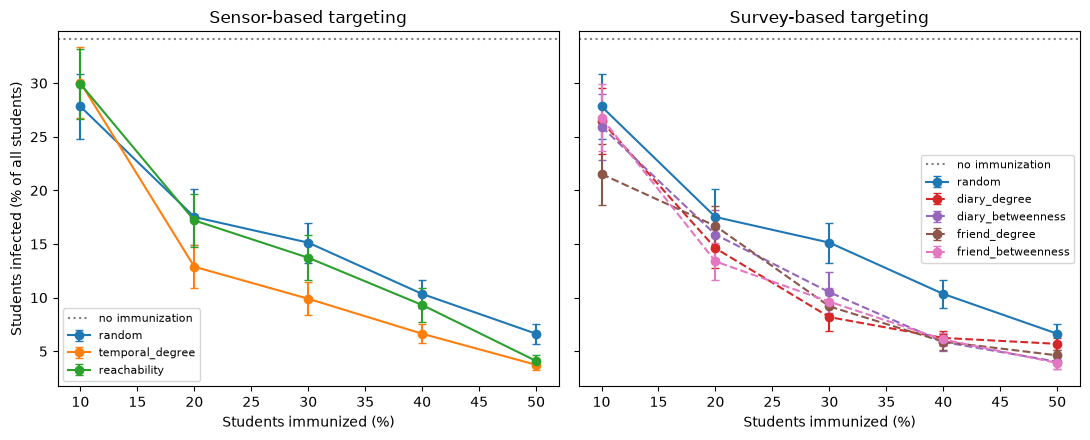

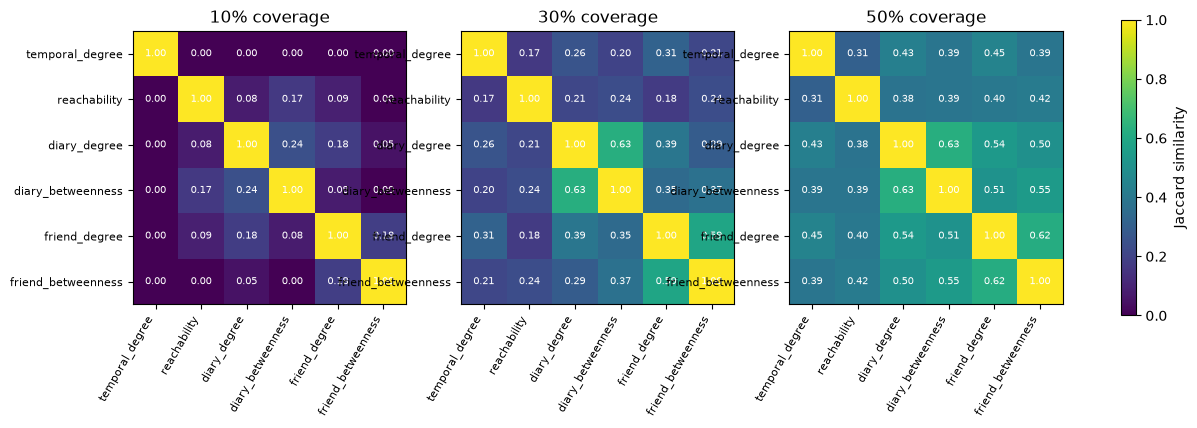

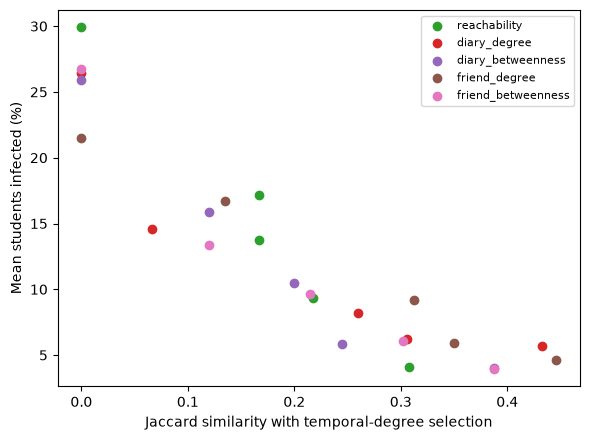

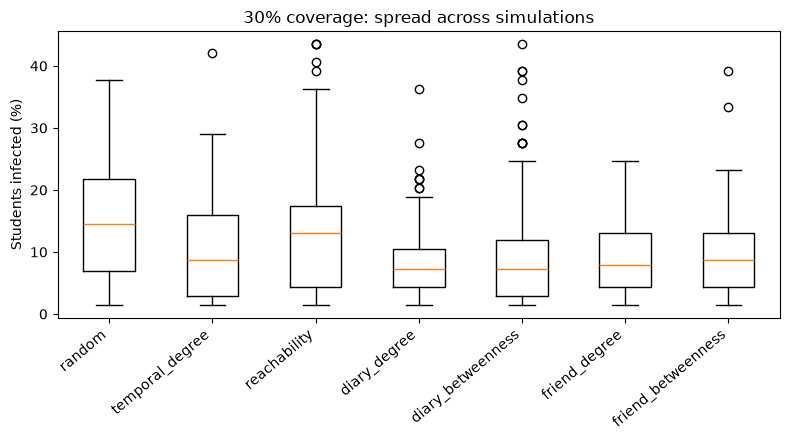

In [20]:
# assign the destination where the figures will be saved
Path("figures").mkdir(exist_ok=True)                    
# assign a consistent color for each immunization strategy
colors = dict(zip(strategies, plt.cm.tab10.colors))     
# this uses the SIR similulation results when there was no immunization to establish a baseline for comparison
base_pct = np.mean(baseline) / N * 100                  

# a function defined to plot the outbreak size for a specific immunization strategy, using the summary statistics and the mean outbreak with error bars
def line(ax, strat, **kw):
    s = summary.filter(pl.col("strategy") == strat)
    ax.errorbar(s["coverage"].to_numpy() * 100, s["mean"].to_numpy() / N * 100,
                yerr=s["ci95"].to_numpy() / N * 100, marker="o", capsize=3, color=colors[strat], label=strat, **kw)

# this plots outbreak size by strategy (left: sensor-based, right: survey-based)
# creating two subplots right next to eachother
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
# iterate over the sensor strategies and plot them on the appropriate subplot, which is axes[0], specifying the left column for sensor-based strategies
for strat in ["random", "temporal_degree", "reachability"]:
    line(axes[0], strat)
# iterate over the survey based strategies and plot them on the appropriate subplot, which is axes[1], specifying the right column for survey-based strategies
for strat in ["random", "diary_degree", "diary_betweenness", "friend_degree", "friend_betweenness"]:
    line(axes[1], strat, ls="--" if strat.startswith(("diary", "friend")) else "-")
# add an appropriate title to each subplot
for ax, title in zip(axes, ["Sensor-based targeting", "Survey-based targeting"]):
    # add a horizontal line indicating the baseline outbreak size with no immunization
    ax.axhline(base_pct, ls=":", color="gray", label="no immunization")
    # set the title, x-axis label, and legend for each subplot 
    ax.set_title(title); ax.set_xlabel("Students immunized (%)"); ax.legend(fontsize=8)
# set the y-axis label, which is the same for both plots
axes[0].set_ylabel("Students infected (% of all students)")
# save the figure
plt.tight_layout(); plt.savefig("figures/fig1_outbreak_size.png", dpi=300); plt.show()

# plot the Jaccard heatmaps at three coverage levels
# create subplot with three different columns, one for each coverage level
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# iterate over the axes and coverage levels to plot the Jaccard heatmaps
for ax, cov in zip(axes, [0.1, 0.3, 0.5]):
    # display the Jaccard heatmap for the current coverage level
    im = ax.imshow(jac[cov], vmin=0, vmax=1, cmap="viridis")
    # set the x and y ticks and labels for the heatmap
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
    # set the title for the current coverage level
    ax.set_title(f"{int(cov * 100)}% coverage")
    # add the Jaccard similarity values as text annotations on the heatmap
    for a in range(len(names)):
        for b in range(len(names)):
            ax.text(b, a, f"{jac[cov][a, b]:.2f}", ha="center", va="center", color="w", fontsize=7)
# add a colorbar to indicate the Jaccard similarity values
fig.colorbar(im, ax=axes, shrink=0.8, label="Jaccard similarity")
plt.savefig("figures/fig2_jaccard.png", dpi=300, bbox_inches="tight"); plt.show()

# create a figure for plotting the relationship between each immunization strategy's overlap with temporal degree and outbreak size
plt.figure(figsize=(6, 4.5))
# get the index of the "temporal_degree" column in the names list
ti = names.index("temporal_degree")
# iterate over each immunization strategy to plot its overlap with temporal degree (jaccard similarity) vs the outbreak size of that strategy
for m in names:
    if m == "temporal_degree":
        continue
    # this is the Jaccard similarity with temporal degree to be used on the x-axis of the plot
    x = [jac[c][ti, names.index(m)] for c in COVERAGES]       
    # this is the mean outbreak size for the current immunization strategy at each coverage level, for the y-axis
    y = [summary.filter((pl.col("strategy") == m) & (pl.col("coverage") == c))["mean"][0] / N * 100 for c in COVERAGES]
    # create the scatter plot
    plt.scatter(x, y, color=colors[m], label=m)
# add the appropriate labels
plt.xlabel("Jaccard similarity with temporal-degree selection")
plt.ylabel("Mean students infected (%)")
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig("figures/fig3_overlap_vs_size.png", dpi=300); plt.show()

# figure showing the distribution of outbreak sizes at 30% coverage
# just use the coverage at 0.3
sub = results.filter(pl.col("coverage") == 0.3)
plt.figure(figsize=(8, 4.5))
# create a boxplot for each immunization strategy
plt.boxplot([sub.filter(pl.col("strategy") == s)["size"].to_numpy() / N * 100 for s in strategies])   # one box per strategy
# add the x-axis labels for the strategies, and set the y-axis label and title for the figure
plt.xticks(range(1, len(strategies) + 1), strategies, rotation=40, ha="right"); plt.ylabel("Students infected (%)"); plt.title("30% coverage: spread across simulations")
plt.tight_layout(); plt.savefig("figures/fig4_distribution.png", dpi=300); plt.show()